# Proyecto Aislamiento Poblacional
Integrantes: Sebastián Castro y María José Ganora

## Dinámica y resolución del sistema

In [1]:
using Pkg
Pkg.add(["Roots","QuadGK"])
using DifferentialEquations
const DE = DifferentialEquations
using Plots
using Roots
using QuadGK


     Project No packages added to or removed from `C:\Users\Sebac\.julia\environments\v1.12\Project.toml`
    Manifest No packages added to or removed from `C:\Users\Sebac\.julia\environments\v1.12\Manifest.toml`


In [2]:
function modelo_sir!(dx, x, p, t)
    b, g, u = p
    S, I = x
    dx[1] = -(1-u)*b*S*I
    dx[2] =  (1-u)*b*S*I - g*I
end

g  = 1/7
R0 = 2.5
b  = R0*g
u  = 0.0
I0 = 1e-3
x0 = [1-I0, I0]            
T  = 200.0

prob = ODEProblem(modelo_sir!, x0, (0.0, T), (b, g, u))
sol = solve(prob);

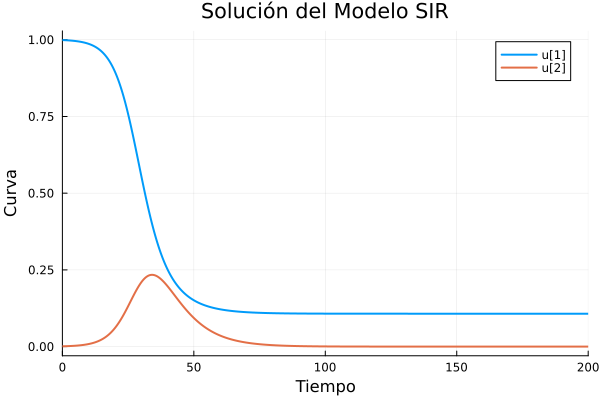

In [3]:
Plots.plot(sol ,xlabel="Tiempo",ylabel="Curva",lw = 2,title = "Solución del Modelo SIR")

### Tamaño Final

In [4]:
Ru = (1-u)*R0
S0 = x0[1]
S_inf_simulado = sol.u[end][1]
S_inf_teorema = find_zero(s -> s - S0*exp(-Ru*(1-s)), (1e-9, 1/Ru))   
println(S_inf_simulado)
println(S_inf_teorema)


1 - S_inf_simulado                                  
g * quadgk(t -> sol(t)[2], 0, T)[1]         

0.10720618303221148
0.10720857207647329


0.8927937948906812

### Verificación

In [5]:
Imax_simulado = maximum(sol[2, :])
Imax_teorema = I0 + S0 - (1/Ru)*(1 + log(Ru*S0))
println(Imax_simulado)
println(Imax_teorema)
k = argmax(sol[2, :])
sol[1, k], 1/Ru

0.23043295829261787
0.2338839073837713


(0.34967760633802747, 0.4)

### Tasa de Crecimiento

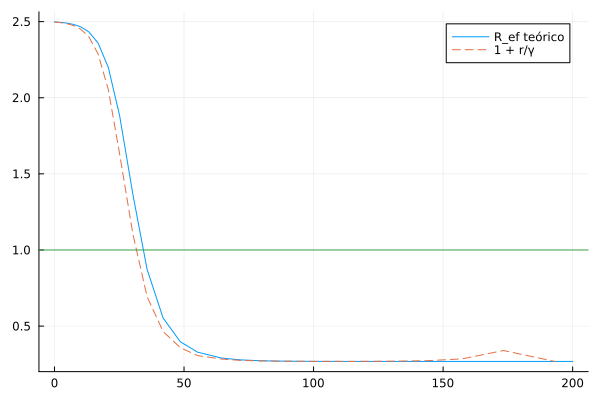

In [6]:
t    = sol.t
S    = sol[1, :]
I    = sol[2, :]

# descartar el final de la simulación, donde I ≈ 0 (o negativo por error numérico)
ok   = I .> 1e-8
tv, Sv, Iv = t[ok], S[ok], I[ok]

R_ef = (1-u)*R0 .* Sv

r = diff(log.(Iv)) ./ diff(tv)
R_ef_est = 1 .+ r ./ g

plot(tv, R_ef, label="R_ef teórico"); plot!(tv[1:end-1], R_ef_est, ls=:dash, label="1 + r/γ")
hline!([1], label="")

## Datos Chile

     Project No packages added to or removed from `C:\Users\Sebac\.julia\environments\v1.12\Project.toml`
    Manifest No packages added to or removed from `C:\Users\Sebac\.julia\environments\v1.12\Manifest.toml`


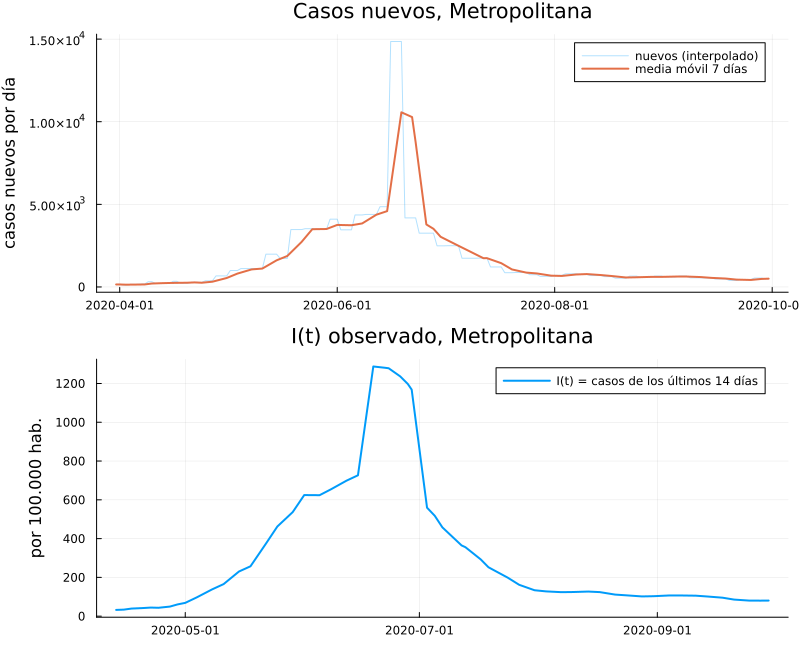

γ = 0.0714,  β = 0.134,  R₀ = 1.88,  I₀ = 0.000272


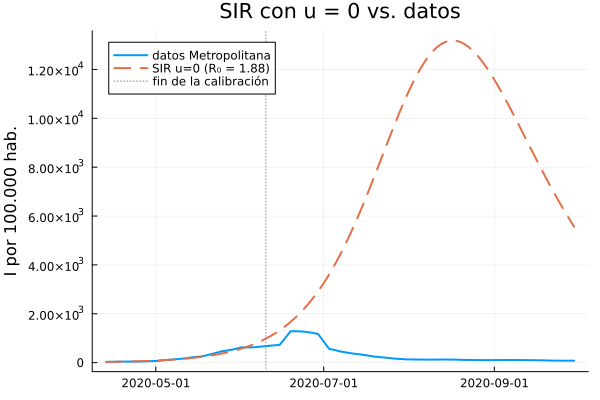

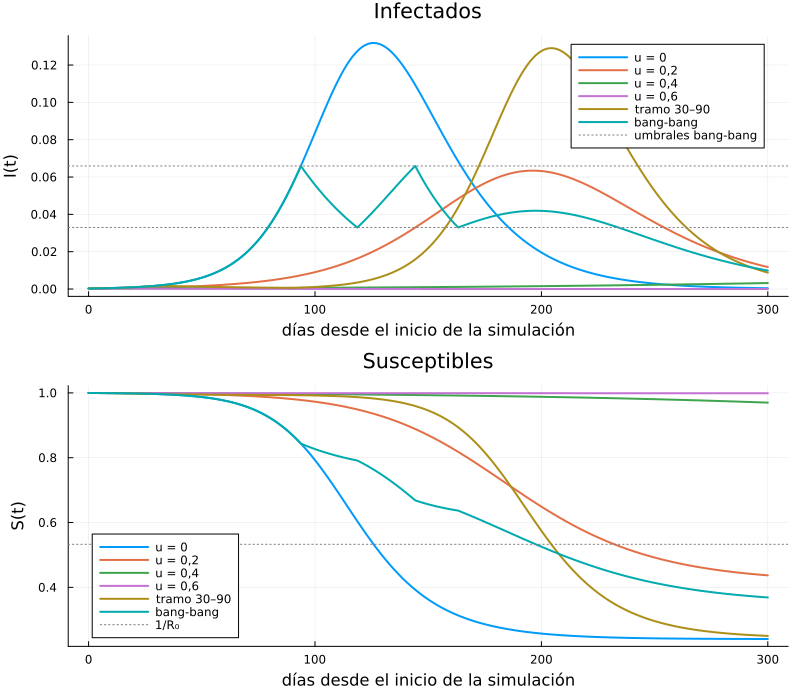

Row,escenario,pico,día_pico,S_final,contagiados_total
,String,Float64,Float64,Float64,Float64
1,u = 0,0.131828,126.0,0.240631,0.759369
2,"u = 0,2",0.0634262,196.0,0.437015,0.562985
3,"u = 0,4",0.00319461,300.0,0.969932,0.0300683
4,"u = 0,6",0.000271831,0.0,0.998916,0.00108395
5,tramo 30–90,0.129043,204.0,0.250157,0.749843
6,bang-bang,0.0659139,93.7513,0.368822,0.631178


In [7]:
Pkg.add(["CSV","DataFrames","Dates","Statistics","Plots","Optim"])
using CSV, DataFrames, Dates, Statistics, Plots, DifferentialEquations, Optim

archivo_csv = "Covid-19.csv"
region      = "Metropolitana"        # región a estudiar
τ           = 14                     # días de infección: γ = 1/τ
fin_calib   = Date(2020, 6, 10)      # último día de la ventana de calibración
fin_plot    = Date(2020, 9, 30)      # hasta dónde se grafican los datos
T_sim       = 300.0                  # días a simular


# DATOS DE CHILE: lectura, acumulado diario, casos nuevos e I(t)
archivo    = CSV.read(archivo_csv, DataFrame)
fijas      = ["Region", "Codigo region", "Comuna", "Codigo comuna", "Poblacion", "Tasa"]
fechas_str = setdiff(names(archivo), fijas)
fechas     = Date.(fechas_str, dateformat"dd-mm-yyyy")
tobs       = Dates.value.(fechas .- fechas[1])

sub = filter(:Region => ==(region), archivo)
N   = sum(skipmissing(sub.Poblacion))
C   = [sum(coalesce.(sub[!, f], 0.0)) for f in fechas_str]     # acumulado por fecha

function interp(tobs, y, tq)                                   # malla diaria
    k = searchsortedlast(tobs, tq)
    k == length(tobs) && return float(y[end])
    return y[k] + (y[k+1] - y[k]) * (tq - tobs[k]) / (tobs[k+1] - tobs[k])
end
Cd = [interp(tobs, C, t) for t in 0:tobs[end]]

nuevos = diff(Cd)                                              # casos nuevos por día
días_n = fechas[1] .+ Day.(1:length(nuevos))
mm7(x) = [mean(x[max(1, i-6):i]) for i in eachindex(x)]        # media móvil 7 días

γ_est  = 1 / τ
I_obs  = (Cd[τ+1:end] .- Cd[1:end-τ]) ./ N                     # I(t): casos de los últimos τ días
días_I = fechas[1] .+ Day.(τ : length(Cd)-1)

# --- Gráfico 1: datos de Chile
mn = días_n .<= fin_plot
mi = días_I .<= fin_plot
p1 = plot(días_n[mn], nuevos[mn], alpha=0.3, label="nuevos (interpolado)",
          ylabel="casos nuevos por día", title="Casos nuevos, $region")
plot!(p1, días_n[mn], mm7(nuevos)[mn], lw=2, label="media móvil 7 días")
p2 = plot(días_I[mi], 1e5 .* I_obs[mi], lw=2, label="I(t) = casos de los últimos $τ días",
          ylabel="por 100.000 hab.", title="I(t) observado, $region")
display(plot(p1, p2, layout=(2, 1), size=(800, 650)))


# MODELO SIR Y ESTIMACIÓN DE PARÁMETROS (β e I₀) EN LA VENTANA INICIAL
function f_sir!(dx, x, p, t)
    β, γ, ufun = p
    u = ufun(t, x)
    dx[1] = -(1 - u) * β * x[1] * x[2]
    dx[2] =  (1 - u) * β * x[1] * x[2] - γ * x[2]
end

u_cero(t, x) = 0.0

function resolver(β, I0, γ, ufun, tfin; saveat=1.0, kwargs...)
    prob = ODEProblem(f_sir!, [1 - I0, I0], (0.0, tfin), (β, γ, ufun))
    solve(prob, Tsit5(); saveat=saveat, reltol=1e-8, abstol=1e-10, kwargs...)
end

i1      = findfirst(>(0), I_obs)                               # primer día con I > 0
ventana = (días_I .>= días_I[i1]) .& (días_I .<= fin_calib)
I_vent  = I_obs[ventana]
t_vent  = Float64.(0:length(I_vent)-1)

function pérdida(θ)
    β, I0 = exp.(θ)                                            # log-parámetros (positivos)
    s = resolver(β, I0, γ_est, u_cero, t_vent[end]; saveat=t_vent)
    length(s.t) == length(t_vent) || return 1e10
    return sum((log.(s[2, :]) .- log.(I_vent)) .^ 2)
end

res = optimize(pérdida, [log(0.3), log(I_vent[1])], NelderMead(),
               Optim.Options(iterations=2000))
β_est, I0_est = exp.(Optim.minimizer(res))
R0_est = β_est / γ_est
println("γ = $(round(γ_est, digits=4)),  β = $(round(β_est, digits=4)),  ",
        "R₀ = $(round(R0_est, digits=2)),  I₀ = $(round(I0_est, sigdigits=3))")


# SIMULACIÓN CON u = 0 vs. LO OCURRIDO EN CHILE
sol_0    = resolver(β_est, I0_est, γ_est, u_cero, T_sim)       # parte en días_I[i1]
días_sim = días_I[i1] .+ Day.(round.(Int, sol_0.t))
ms       = días_sim .<= fin_plot

p3 = plot(días_I[mi], 1e5 .* I_obs[mi], lw=2, label="datos $region",
          ylabel="I por 100.000 hab.", title="SIR con u = 0 vs. datos")
plot!(p3, días_sim[ms], 1e5 .* sol_0[2, ms], lw=2, ls=:dash,
      label="SIR u=0 (R₀ = $(round(R0_est, digits=2)))")
vline!(p3, [fin_calib], ls=:dot, color=:gray, label="fin de la calibración")
display(p3)


# 4. DISTINTOS CONTROLES SOBRE LA EDO CON LOS PARÁMETROS ESTIMADOS
# u constante
sol_02 = resolver(β_est, I0_est, γ_est, (t, x) -> 0.2, T_sim)
sol_04 = resolver(β_est, I0_est, γ_est, (t, x) -> 0.4, T_sim)
sol_06 = resolver(β_est, I0_est, γ_est, (t, x) -> 0.6, T_sim)

# confinamiento en un tramo: entre los días 30 y 90
sol_tr = resolver(β_est, I0_est, γ_est,
                  (t, x) -> (30.0 <= t <= 90.0 ? 0.6 : 0.0), T_sim; tstops=[30.0, 90.0])

# bang-bang con umbrales: se activa al subir de I_on, se levanta al bajar de I_off
pico_0 = maximum(sol_0[2, :])
I_on, I_off, umax_c = 0.5 * pico_0, 0.25 * pico_0, 0.6
estado  = Ref(false)                                           # true = confinamiento activo
cambios = Tuple{Float64,Bool}[]                                # (día, nuevo estado)

cb_on  = ContinuousCallback((x, t, integ) -> x[2] - I_on,
                            integ -> (estado[] = true;  push!(cambios, (integ.t, true))), nothing)
cb_off = ContinuousCallback((x, t, integ) -> x[2] - I_off,
                            nothing, integ -> (estado[] = false; push!(cambios, (integ.t, false))))

estado[] = false; empty!(cambios)
sol_bb = resolver(β_est, I0_est, γ_est, (t, x) -> (estado[] ? umax_c : 0.0), T_sim;
                  callback=CallbackSet(cb_on, cb_off))

# --- Gráfico 4
escenarios = ["u = 0" => sol_0, "u = 0,2" => sol_02, "u = 0,4" => sol_04,
              "u = 0,6" => sol_06, "tramo 30–90" => sol_tr, "bang-bang" => sol_bb]

p4 = plot(xlabel="días desde el inicio de la simulación", ylabel="I(t)", title="Infectados")
p5 = plot(xlabel="días desde el inicio de la simulación", ylabel="S(t)", title="Susceptibles")
for (nombre, s) in escenarios
    plot!(p4, s.t, s[2, :], lw=2, label=nombre)
    plot!(p5, s.t, s[1, :], lw=2, label=nombre)
end
hline!(p4, [I_on, I_off], ls=:dot, color=:gray, label="umbrales bang-bang")
hline!(p5, [1 / R0_est], ls=:dot, color=:gray, label="1/R₀")
display(plot(p4, p5, layout=(2, 1), size=(800, 700)))

# --- Tabla resumen
function resumen_p4(nombre, s)
    inf = s[2, :]; k = argmax(inf)
    (escenario=nombre, pico=inf[k], día_pico=s.t[k], S_final=s[1, end],
     contagiados_total=1 - s[1, end])
end
DataFrame([resumen_p4(n, s) for (n, s) in escenarios])

### **Resolviendo el modelo SIR usando PMP**

Primero partiremos analizando el problema con la función objetivo $$J(u) := \int_{0}^{300} (I(t)+ u^2(t))dt$$ usando dos métodos diferentes:

1.- Resolviendo directamente con Optimal Control.

2.- Usando el método de shooting visto en laboratorio.

Cargamos las librerias


In [8]:
using Plots, DifferentialEquations, NonlinearSolve, OptimalControl, NLPModelsIpopt

Definimos los parametros a usar

In [9]:
beta=0.134
gamma=0.0714
I0=0.000272
T=365

365

**1) Método directo usando Optimal Control** y los parametros encontrados antes:

▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation
   ├─ Modeler: adnlp
   └─ Solver: ipopt

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:     2502
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:     2001

Total number of variables............................:      752
                     variables with only lower bounds:        0
                variables with lower and upper bounds:      250
                     variables with only upper bounds:        0
Total number of equality constraints.................:      502
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper b

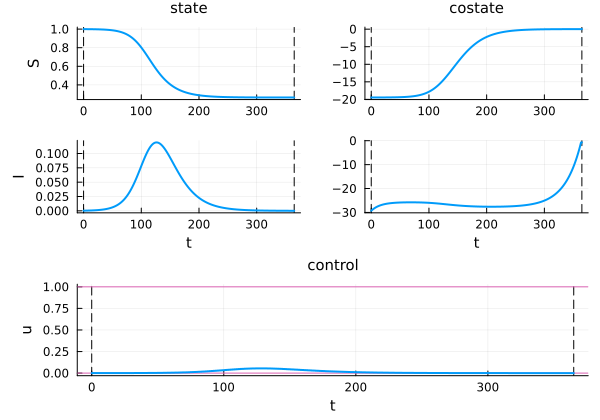

In [10]:
@def ocp1 begin
    z=(S,I) ∈ R², state
    t ∈ [0,T], time
    u ∈ R, control

    z(0)==[1 - I0,I0]

    0.0 ≤ u(t) ≤ 1.0

    ż(t) ==[-(1 - u(t)) * beta * z[1](t) * z[2](t) , (1 - u(t)) * beta * z[1](t) * z[2](t) - gamma * z[2](t)]

    ∫((I(t)) + (u(t))^2 )→ min

end
sol1=solve(ocp1)
plot(sol1)

2) **Ahora resolvemos usando el método de shooting**

Para hacer esto debemos desarrollar PMP para obtener el candidato a control optimal, obteniendo:


In [11]:
#Control optimal dado por PMP
function control_optimo1(S,I,pS,pI)
    u_libre=beta*S*I*(pI-pS)/2
    if u_libre <=0.0
        return 0.0
    elseif 0.0 <= u_libre <= 1.0
        return u_libre
    else
        return 1.0
    end
end

control_optimo1 (generic function with 1 method)

Definimos tanto la dinamica del sistema junto a los coestados y además calculamos la función residuo que pide el método

In [12]:
#Dinamica del sistema acoplado con los co-estados
function sistema_acoplado!(dw,w,p,t)
    S, I, pS, pI =w
    u=control_optimo1(S,I,pS,pI)
    dw[1]=-(1-u)*beta*w[1]*w[2]
    dw[2]=(1-u)*beta*w[1]*w[2] - gamma*I
    dw[3]=(1-u)*beta*w[2]*pS - pI*(1-u)*beta*w[2]
    dw[4]= -1 + pS*(1-u)*beta*w[1] - pI*(1-u)*beta*w[1] + gamma*pI
end

#Calculamos el residuo
function residuo!(F, λ0,p)
    prob = ODEProblem(sistema_acoplado!, [1-I0, I0, λ0[1], λ0[2]], (0.0, T))
    sol  = solve(prob, Tsit5(); reltol=1e-10, abstol=1e-12)
    F .= sol.u[end][3:4]
    return F          # λ(T) = 0
end

#Obtenemos los optimos de p_I y p_S
λ_guess = [19.0, 60.0]                      
prob_nl = NonlinearProblem(residuo!, λ_guess)
sol_shooting = solve(prob_nl, TrustRegion(autodiff = AutoFiniteDiff());
                     abstol = 1e-10)
p0_opt = sol_shooting.u
println("λ(0) = ", p0_opt, "   ‖F‖ = ", maximum(abs.(sol_shooting.resid)))

λ(0) = [19.456408934098828, 29.489398147437623]   ‖F‖ = 8.167424447216353e-11


Modelamos y graficamos

In [13]:
prob = ODEProblem(sistema_acoplado!, [1 - I0, I0, p0_opt[1], p0_opt[2]], (0.0, T))
sol  = solve(prob, Tsit5(); reltol=1e-10, abstol=1e-12)
ts   = range(0, T, length=1001)
Y    = reduce(hcat, sol.(ts))
Sv, Iv = Y[1, :], Y[2, :]
u    = control_optimo1.(Sv, Iv, Y[3, :], Y[4, :])


1001-element Vector{Float64}:
 0.0001827914626187309
 0.0001854092554586333
 0.00018808738618311037
 0.00019082724147989133
 0.00019363023971655954
 0.00019649783165608892
 0.00019943150118388044
 0.00020243276606153558
 0.00020550317868394023
 0.00020864432685639673
 0.00021185783460757904
 0.0002151453629727421
 0.0002185086108707835
 ⋮
 4.9623793257374264e-6
 4.481059662676596e-6
 4.0060181171044525e-6
 3.5371728409547374e-6
 3.07444305184435e-6
 2.617749019773136e-6
 2.1670120530402745e-6
 1.7221544850632134e-6
 1.2830996607620689e-6
 8.497719237183786e-7
 4.2209660284088636e-7
 0.0

Rₑ(0) = 1.876   |   Rₑ(T) = 0.496
Rₑ < 1 desde t = 126.7 días (con control)
Rₑ < 1 desde t = 125.9 días (sin control)
Peak de I en t = 126.7 días


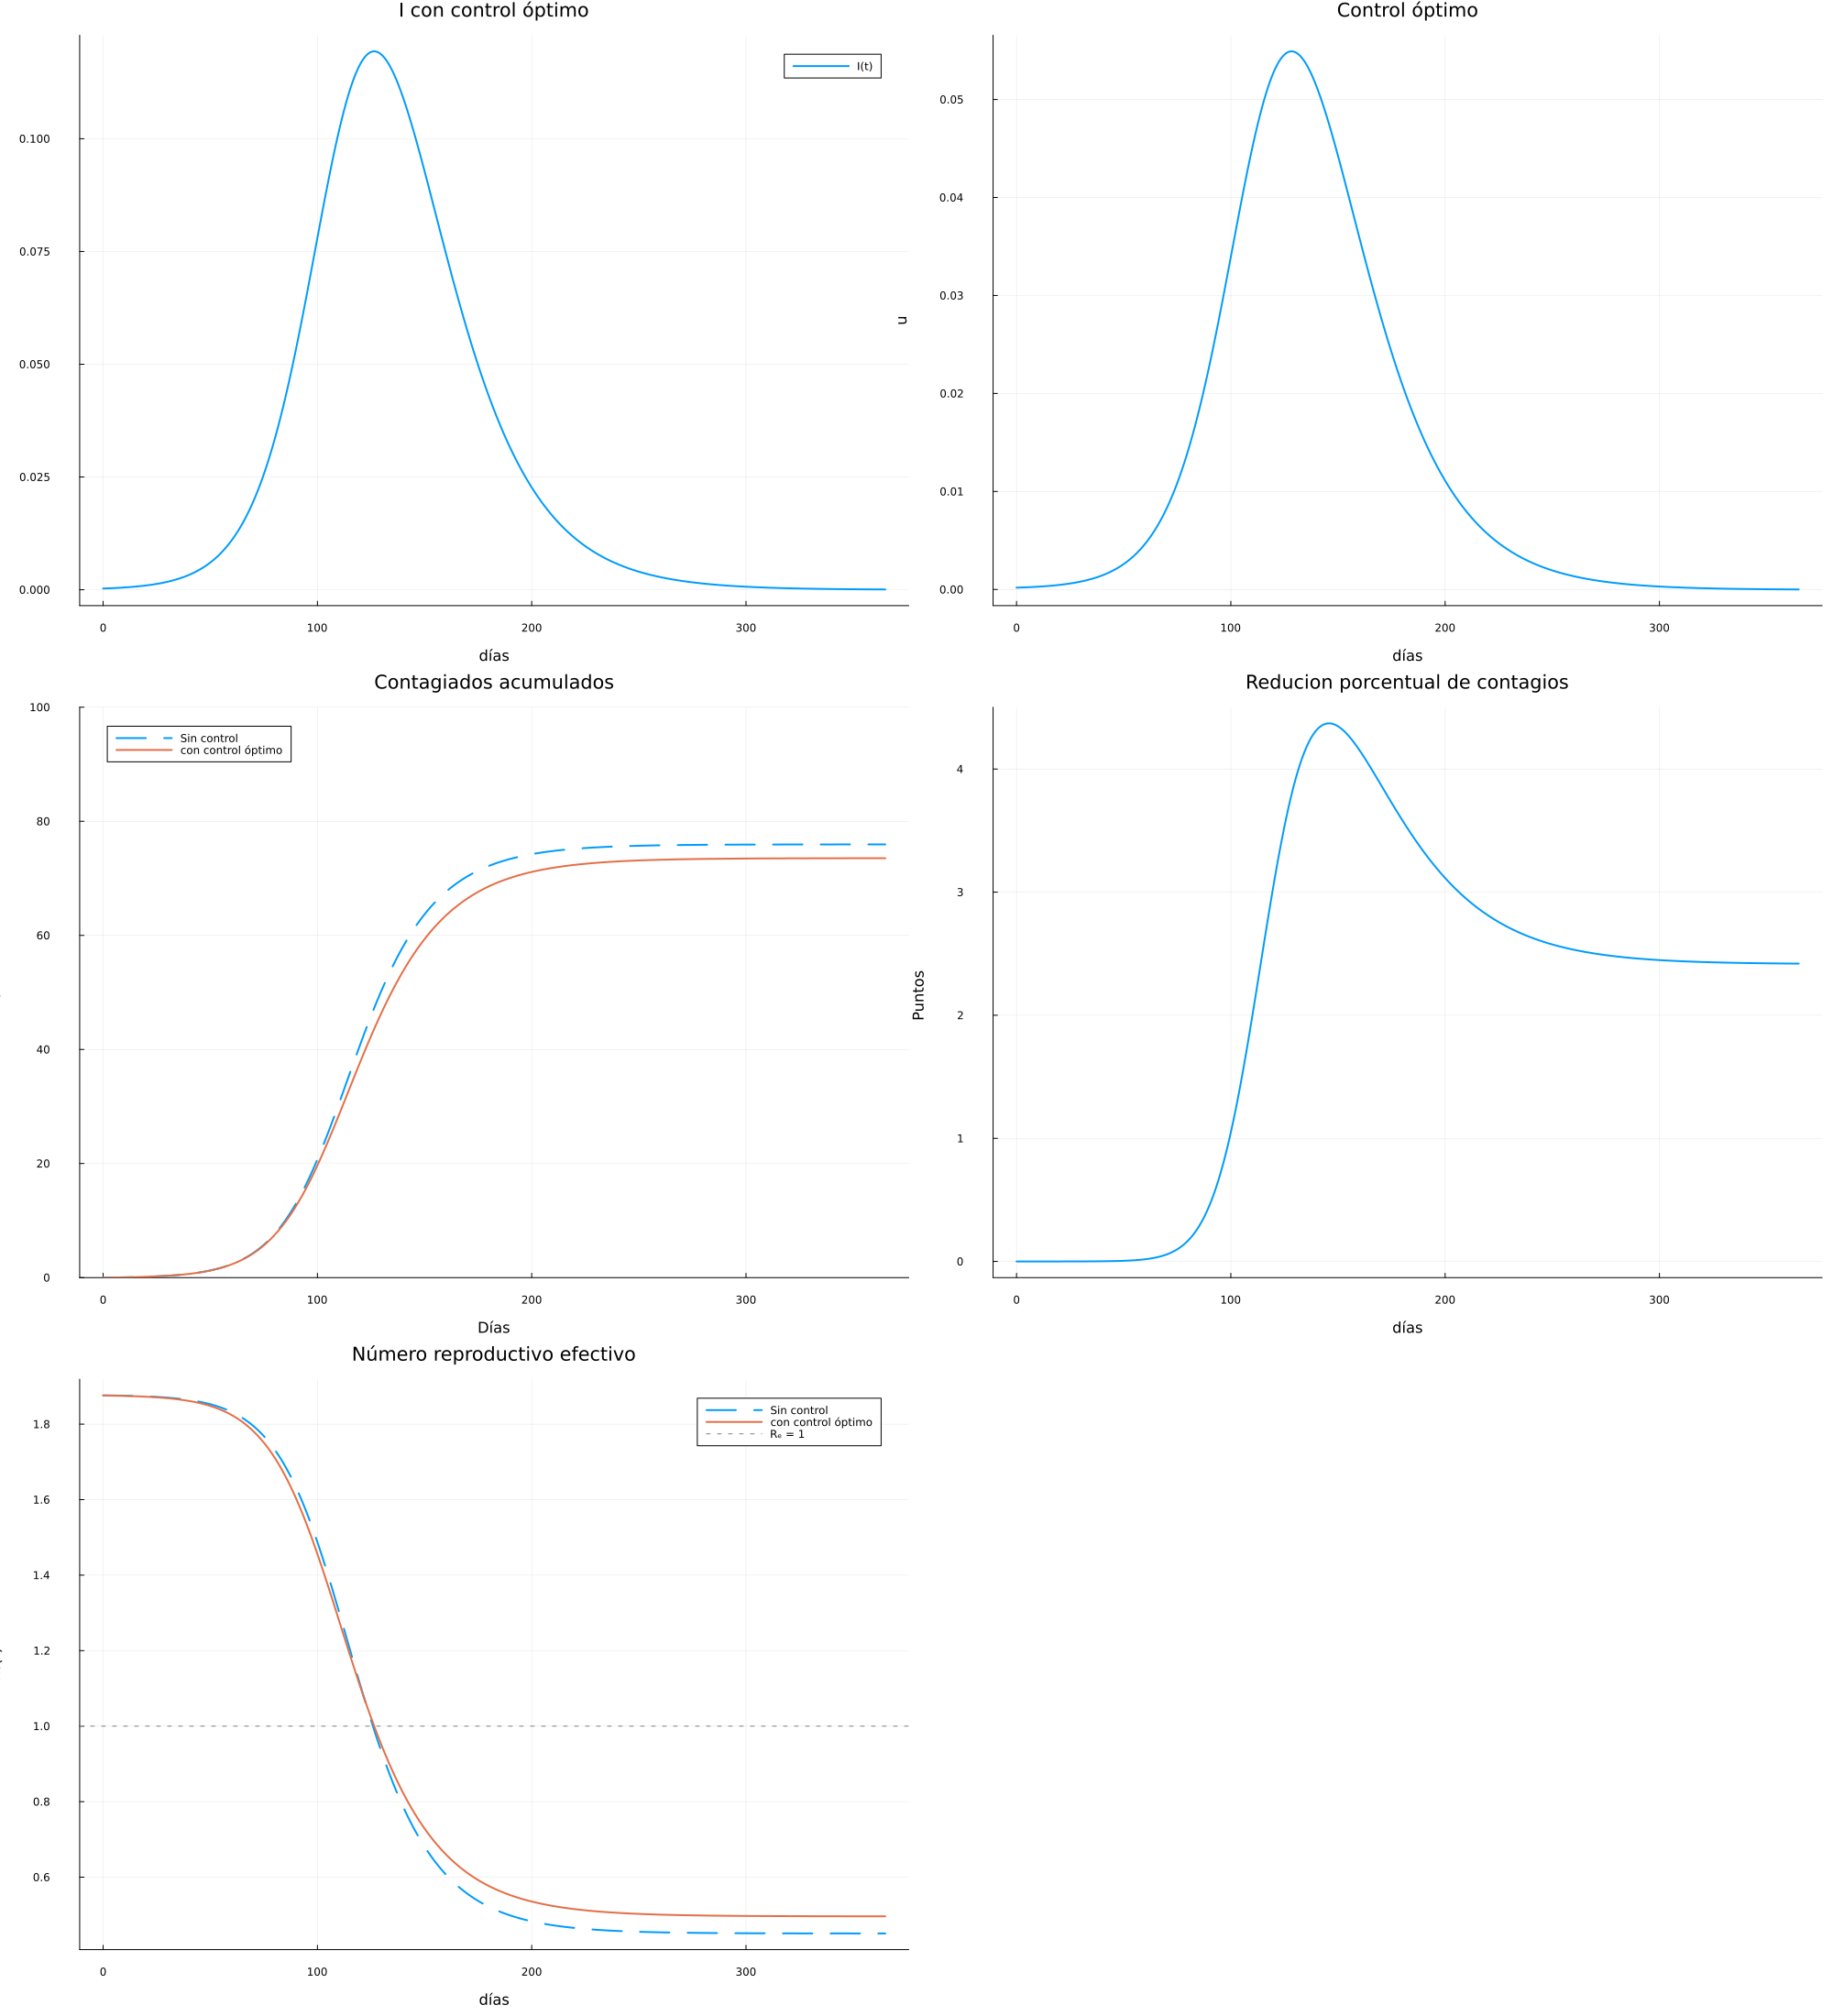

In [14]:


#Primero graficamos I(t)
p1 = plot(ts, Iv, lw=2, label="I(t)", xlabel="días", ylabel="Infectados",
          title="I con control óptimo")
#Graficamos el control óptimo u a tiempo t 
p2 = plot(ts, u, lw=2, xlabel="días", ylabel="u", title="Control óptimo", legend=false)

#Calculamos los infectados acumulados en cada instante en presencia del control
C  = 100 .* ((1 - I0) .- Sv)          

# modelamos sin control para obtener los infectados acumulados cuando no hay intervención
sincontrol_1!(dy, y, p, t) = (dy[1] = -beta*y[1]*y[2]; dy[2] = beta*y[1]*y[2] - gamma*y[2])
Y0 = reduce(hcat, solve(ODEProblem(sincontrol_1!, [1 - I0, I0], (0.0, T)), Tsit5();
                        reltol=1e-10, abstol=1e-12).(ts))
#infectados acumulados sin intervención  
C0 = 100 .* ((1 - I0) .- Y0[1, :])

#Grafico de los infectados acumulados a tiempo t 
p3 = plot(ts, C0, lw=2, ls=:dash, label="Sin control", xlabel="Días",
          ylabel="% de la población", title="Contagiados acumulados", ylims=(0, 100))
plot!(p3, ts, C, lw=2, label="con control óptimo")

#graficamos además la diferencia porcentual entre cuantos se contagiaron con y sin control en el instante t 
p4 = plot(ts, C0 .- C, lw=2, xlabel="días", ylabel="Puntos ",
          title="Reducion porcentual de contagios", legend=false)

#Calculamos el numero reproductivo basico y efectivo en presencia de un control
R0   = beta / gamma
Re   = (1 .- u) .* R0 .* Sv          #Con control óptimo
Re0  = R0 .* Y0[1, :]                #Sin control óptimo
#vemos la evolución del numero reproductivo efectivo
p5 = plot(ts, Re0, lw=2, ls=:dash, label="Sin control",
          xlabel="días", ylabel="Rₑ(t)", title="Número reproductivo efectivo")
plot!(p5, ts, Re, lw=2, label="con control óptimo")
hline!(p5, [1.0], ls=:dot, color=:gray, label="Rₑ = 1")

# día en que Rₑ cruza la barrera del 1 
k  = findfirst(<(1.0), Re)
k0 = findfirst(<(1.0), Re0)
println("Rₑ(0) = ", round(Re[1], digits=3), "   |   Rₑ(T) = ", round(Re[end], digits=3))
println("Rₑ < 1 desde t = ", isnothing(k)  ? "nunca" : round(ts[k],  digits=1), " días (con control)")
println("Rₑ < 1 desde t = ", isnothing(k0) ? "nunca" : round(ts[k0], digits=1), " días (sin control)")
println("Peak de I en t = ", round(ts[argmax(Iv)], digits=1), " días")

plot(p1, p2, p3, p4, p5, layout=(3, 2), size=(2000, 2200))

Ahora cambiaremos la función de costo a
$$J(v)=\int_{0}^{300}I(t)+0.1u^2(t)+100v^2(t)dt$$

donde $v(t)=\dot{u}(t)$, pasando el control de confinamiento a una variable de estado y controlando sobre la velocidad en la que se cambia el aislamiento poblacional

In [15]:
#Tomaremos los siguientes c y rho
c2=0.1
rho=100.0

100.0

**1) Con Optimal Control**

In [16]:

@def ocp2 begin
    z=(S,I,u) ∈ R³, state
    t ∈ [0,T], time
    v ∈ R, control

    z(0)==[1 - I0,I0,0.0]
    0.0 ≤ u(t) ≤ 1.0
    -0.05 ≤ v(t) ≤ 0.05

    ż(t) ==[-(1 - u(t)) * beta * z[1](t) * z[2](t) , (1 - u(t)) * beta * z[1](t) * z[2](t) - gamma * z[2](t),v(t)]

    ∫((I(t)) + c2*(u(t))^2 + rho*v(t)^2 )→ min

end
sol2 = solve(ocp2; grid_size = 1000, max_iter = 1200, display = true)

▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation (grid_size = 1000)
   ├─ Modeler: adnlp
   └─ Solver: ipopt (max_iter = 1200)

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:    15003
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:    12004

Total number of variables............................:     4003
                     variables with only lower bounds:        0
                variables with lower and upper bounds:     2001
                     variables with only upper bounds:        0
Total number of equality constraints.................:     3003
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        ine

• Solver:
  ✓ Successful  : true
  │  Status     : first_order
  │  Message    : Ipopt/generic
  │  Iterations : 16
  │  Objective  : 6.708716127345148
  └─ Constraints violation : 1.1102230246251565e-16

• Boundary duals: [-18.780350377348654, -2618.913047390035, 3.0090886476391043]


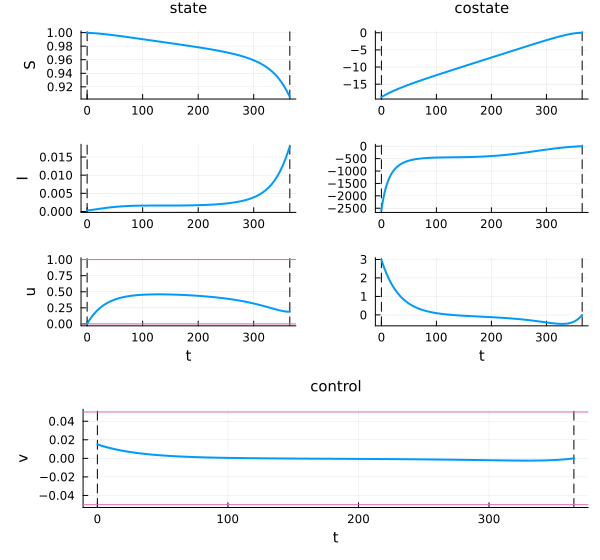

In [17]:
plot(sol2)

**2) Ahora resolvamos con shooting**

In [18]:
#Control optimal dado por PMP
function control_optimo2(S,I,u,pS,pI,pu)
    u_libre=-pu/(2*rho)
    if u_libre <=-0.05
        return -0.05
    elseif -0.05 <= u_libre <= 0.05
        return u_libre
    else
        return 0.05
    end
end

#Dinamica del sistema acoplado con los co-estados
function sistema_acoplado2!(dw,w,p,t)
    S, I,u, pS, pI, pu =w
    v=control_optimo2(S,I,u,pS,pI,pu)
    dw[1]=-(1-u)*beta*w[1]*w[2]
    dw[2]=(1-u)*beta*w[1]*w[2] - gamma*I
    dw[3]= v
    dw[4]=(1-u)*beta*w[2]*pS - pI*(1-u)*beta*w[2]
    dw[5]= -1 + pS*(1-u)*beta*w[1] - pI*(1-u)*beta*w[1] + gamma*pI
    dw[6]=-2*c2*w[3] - pS*beta*w[1]*w[2] + pI*beta*w[1]*w[2]

end

#Calculamos el residuo
function residuo2!(F, λ0,p)
    prob = ODEProblem(sistema_acoplado2!, [1-I0, I0, 0.0, λ0[1], λ0[2], λ0[3]], (0.0, T))
    sol  = solve(prob, Tsit5(); reltol=1e-10, abstol=1e-12)
    F .= sol.u[end][4:6]
    return F          # λ(T) = 0
end

λ_guess = [18.78, 2618.92, -3.0]                      
prob_nl = NonlinearProblem(residuo2!, λ_guess)
sol_shooting2 = solve(prob_nl, TrustRegion(autodiff = AutoFiniteDiff());
                     abstol = 1e-10)
p0_opt2 = sol_shooting2.u
println("λ(0) = ", p0_opt2, "   ‖F‖ = ", maximum(abs.(sol_shooting2.resid)))

λ(0) = [18.780189186161966, 2618.920714059119, -3.0079698078285584]   ‖F‖ = 9.775074520027638e-11


Modelamos y graficamos

Rₑ(0) = 1.876   |   Rₑ(T) = 1.378
Rₑ mínimo = 1.001 en t = 134.3 días
Rₑ < 1 desde t = nunca
u máximo = 0.46 en t = 128.8 días


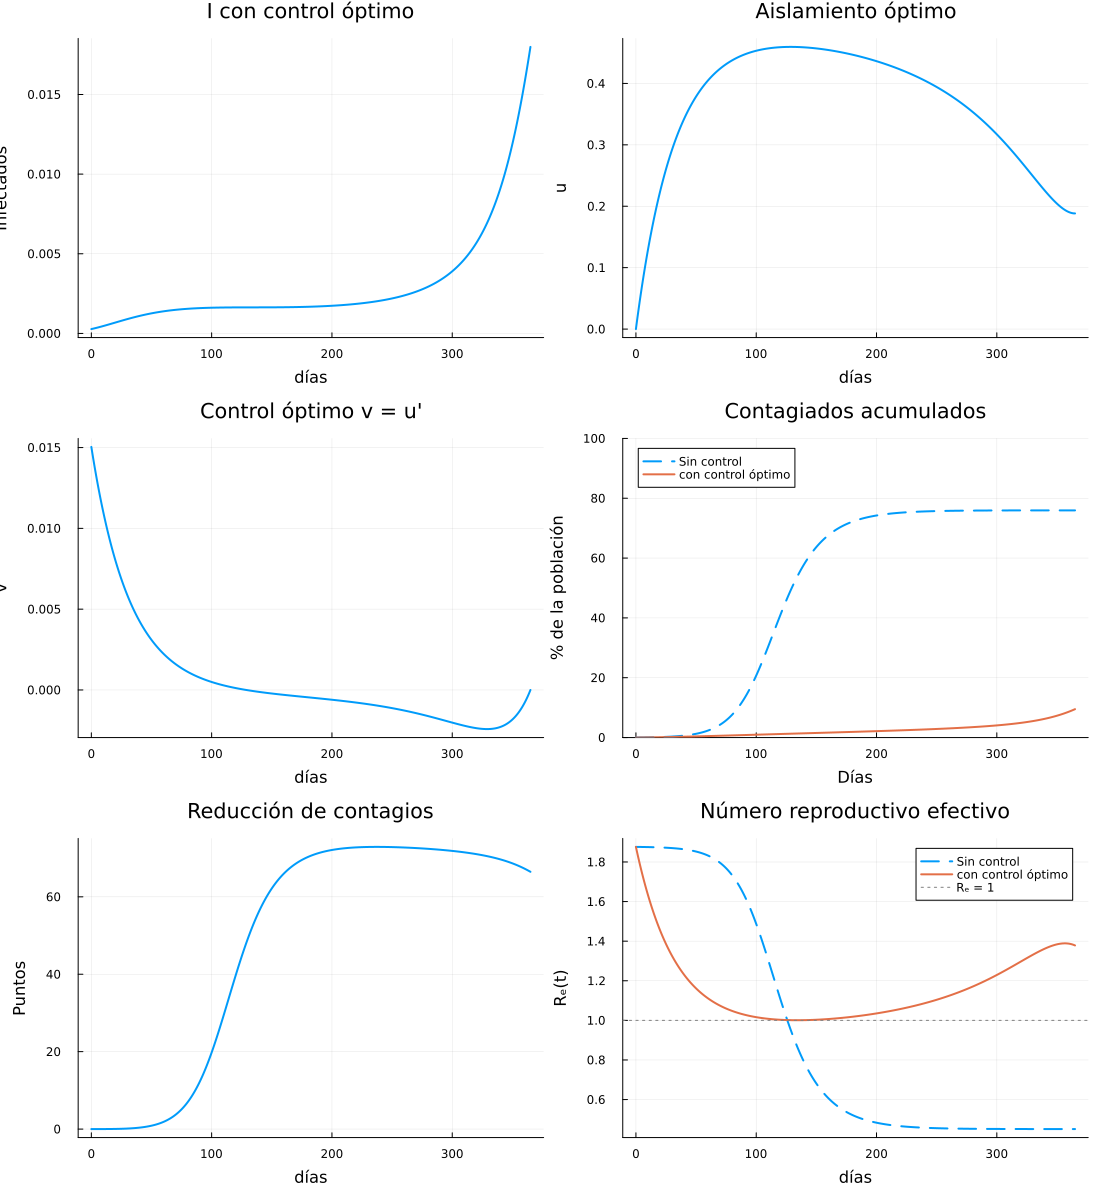

In [19]:
prob2   = ODEProblem(sistema_acoplado2!, [1 - I0, I0, 0.0, p0_opt2...], (0.0, T))
sol_ode = solve(prob2, Vern9(); reltol=1e-13, abstol=1e-15)
ts = range(0, T, length=1001)
Y  = reduce(hcat, sol_ode.(ts))
Sv, Iv, uv = Y[1, :], Y[2, :], Y[3, :]
v  = control_optimo2.(Sv, Iv, uv, Y[4, :], Y[5, :], Y[6, :])

#Grafico de I(t)
p1 = plot(ts, Iv, lw=2, xlabel="días", ylabel="Infectados", title="I con control óptimo", legend=false)

#Grafico de u(t)
p2 = plot(ts, uv, lw=2, xlabel="días", ylabel="u", title="Aislamiento óptimo", legend=false)

#grafico de v(t)
pv = plot(ts, v,  lw=2, xlabel="días", ylabel="v", title="Control óptimo v = u'", legend=false)

#Calculamos los infectados acumulados en tiempo t  y los graficamos para comparar si es que no hubiera control
C  = 100 .* ((1 - I0) .- Sv)
p3 = plot(ts, C0, lw=2, ls=:dash, label="Sin control", xlabel="Días",
          ylabel="% de la población", title="Contagiados acumulados", ylims=(0, 100))
plot!(p3, ts, C, lw=2, label="con control óptimo")

#Graficamos la diferencia porcentual
p4 = plot(ts, C0 .- C, lw=2, xlabel="días", ylabel="Puntos", title="Reducción de contagios", legend=false)

plot(p1, p2, pv, p3, p4; layout=(3, 2), size=(1100, 1000))

#Calculamos el numero reproductivo basico y efectivo
R0   = beta / gamma
Re   = (1 .- uv) .* R0 .* Sv                 # con control óptimo

#Volvemos a modelar sin control 
sincontrol_2!(dy, y, p, t) = (dy[1] = -beta*y[1]*y[2]; dy[2] = beta*y[1]*y[2] - gamma*y[2])
Y0   = reduce(hcat, solve(ODEProblem(sincontrol_2!, [1 - I0, I0], (0.0, T)), Tsit5();
                          reltol=1e-10, abstol=1e-12).(ts))
Re0  = R0 .* Y0[1, :]   #sin control

#graficamos la evolucion en el tiempo del numero reproductivo efectivo.
p5 = plot(ts, Re0, lw=2, ls=:dash, label="Sin control",
          xlabel="días", ylabel="Rₑ(t)", title="Número reproductivo efectivo")
plot!(p5, ts, Re, lw=2, label="con control óptimo")
hline!(p5, [1.0], ls=:dot, color=:gray, label="Rₑ = 1")

kmin = argmin(Re)
k    = findfirst(<(1.0), Re)
println("Rₑ(0) = ", round(Re[1], digits=3), "   |   Rₑ(T) = ", round(Re[end], digits=3))
println("Rₑ mínimo = ", round(Re[kmin], digits=3), " en t = ", round(ts[kmin], digits=1), " días")
println("Rₑ < 1 desde t = ", isnothing(k) ? "nunca" : round(ts[k], digits=1))
println("u máximo = ", round(maximum(uv), digits=3), " en t = ", round(ts[argmax(uv)], digits=1), " días")

plot(p1, p2, pv, p3, p4, p5; layout=(3, 2), size=(1100, 1200))

### Comparación entre Optimal Control y PMP (Shooting Method) para \(J_2\)

Se comparan las trayectorias de infectados \(I(t)\) y el nivel de aislamiento \(u(t)\) obtenidas con ambos métodos.

In [ ]:
# Extraemos las trayectorias de la solución obtenida con Optimal Control.
# state(sol2) entrega (S, I, u) y control(sol2) entrega v = du/dt.
x_ocp = state(sol2)
v_ocp = control(sol2)

# Evaluamos ambas soluciones en la misma malla temporal.
I_ocp = [x_ocp(t)[2] for t in ts]
u_ocp = [x_ocp(t)[3] for t in ts]

# Comparación de infectados I(t)
p_I = plot(ts, I_ocp, lw=2.5, label="Optimal Control",
           xlabel="Días", ylabel="Proporción de infectados",
           title="Comparación de infectados: J₂")
plot!(p_I, ts, Iv, lw=2.5, ls=:dash, label="PMP (Shooting)")

# Comparación del nivel de aislamiento u(t)
p_u = plot(ts, u_ocp, lw=2.5, label="Optimal Control",
           xlabel="Días", ylabel="Nivel de aislamiento u(t)",
           title="Comparación del aislamiento: J₂",
           ylims=(0, 1))
plot!(p_u, ts, uv, lw=2.5, ls=:dash, label="PMP (Shooting)")

display(plot(p_I, p_u; layout=(2, 1), size=(950, 750)))

# Comparación de los valores de la función objetivo J₂.
# Para PMP integramos numéricamente usando la regla del trapecio.
integrando_pmp = Iv .+ c2 .* uv.^2 .+ rho .* v.^2
J2_pmp = sum((integrando_pmp[1:end-1] .+ integrando_pmp[2:end]) ./ 2 .* diff(ts))

println("J₂ Optimal Control = ", round(sol2.objective, digits=6))
println("J₂ PMP (Shooting)  = ", round(J2_pmp, digits=6))

Ahora resolveremos con el siguiente costo: 
$$J(u)= \int_{0}^{365} I(t) + cu^2(t)+ a (I(t)-I_{max})^2dt$$

Que penaliza a la proporcion de infectados por estar lejos de 0.1.

**1) Usando Oprimal Control**

In [20]:
c3=1
a=1000
Imax=0.1

0.1

In [21]:
@def ocp3 begin
    z = (S, I) ∈ R², state
    t ∈ [0, T], time
    u ∈ R, control

    z(0) == [1 - I0, I0]
    0 ≤ u(t) ≤ 1.0

    ż(t) == [-(1 - u(t)) * beta * z[1](t) * z[2](t),
              (1 - u(t)) * beta * z[1](t) * z[2](t) - gamma * z[2](t)]

    ∫( I(t) + c3* u(t)^2 + a * max(I(t) - Imax, 0.0)^2 ) → min
end
sol3 = solve(ocp3)
println("J directo = ", objective(sol3))

▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation
   ├─ Modeler: adnlp
   └─ Solver: ipopt

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:     2502
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:     2502

Total number of variables............................:      752
                     variables with only lower bounds:        0
                variables with lower and upper bounds:      250
                     variables with only upper bounds:        0
Total number of equality constraints.................:      502
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper b

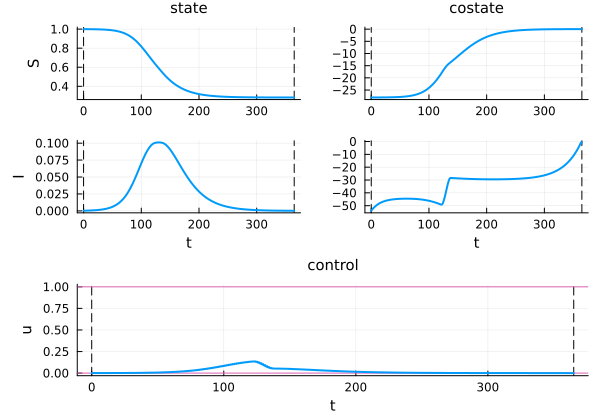

In [22]:
plot(sol3)


**2) usando Shooting**

El control optimal que da PMP es el mismo que en la función 1

In [23]:

#Dinamica del sistema acoplado con los co-estados
function sistema_acoplado3!(dw,w,p,t)
    S, I, pS, pI =w
    u=control_optimo1(S,I,pS,pI)
    dw[1]=-(1-u)*beta*w[1]*w[2]
    dw[2]=(1-u)*beta*w[1]*w[2] - gamma*I
    dw[3]=(1-u)*beta*w[2]*pS - pI*(1-u)*beta*w[2]
    dw[4] = -1 - 2*a*max((w[2] - Imax),0.0) + pS*(1-u)*beta*w[1] - pI*(1-u)*beta*w[1] + gamma*pI
end


#Calculamos el residuo
function residuo3!(F, λ0,p)
    prob = ODEProblem(sistema_acoplado3!, [1-I0, I0, λ0[1], λ0[2]], (0.0, T))
    sol  = solve(prob, Tsit5(); reltol=1e-12, abstol=1e-12)
    F .= sol.u[end][3:4]
    return F          # λ(T) = 0
end

λ_guess = [28.06, 51.56]                      
prob_nl = NonlinearProblem(residuo3!, λ_guess)
sol_shooting3 = solve(prob_nl, TrustRegion(autodiff = AutoFiniteDiff());
                     abstol = 1e-10)
p0_opt3 = sol_shooting3.u

println("λ(0) = ", p0_opt3, "   ‖F‖ = ", maximum(abs.(sol_shooting3.resid)))

λ(0) = [28.06240850600903, 51.55701340512974]   ‖F‖ = 2.751777879491877e-8


Modelamos y graficamos

Rₑ(0) = 1.875   |   Rₑ(T) = 0.53
Rₑ < 1 desde t = 130.7 días (con control)
Rₑ < 1 desde t = 125.9 días (sin control)
Peak de I = 0.101 en t = 130.3 días
u máximo  = 0.1355 en t = 123.0 días


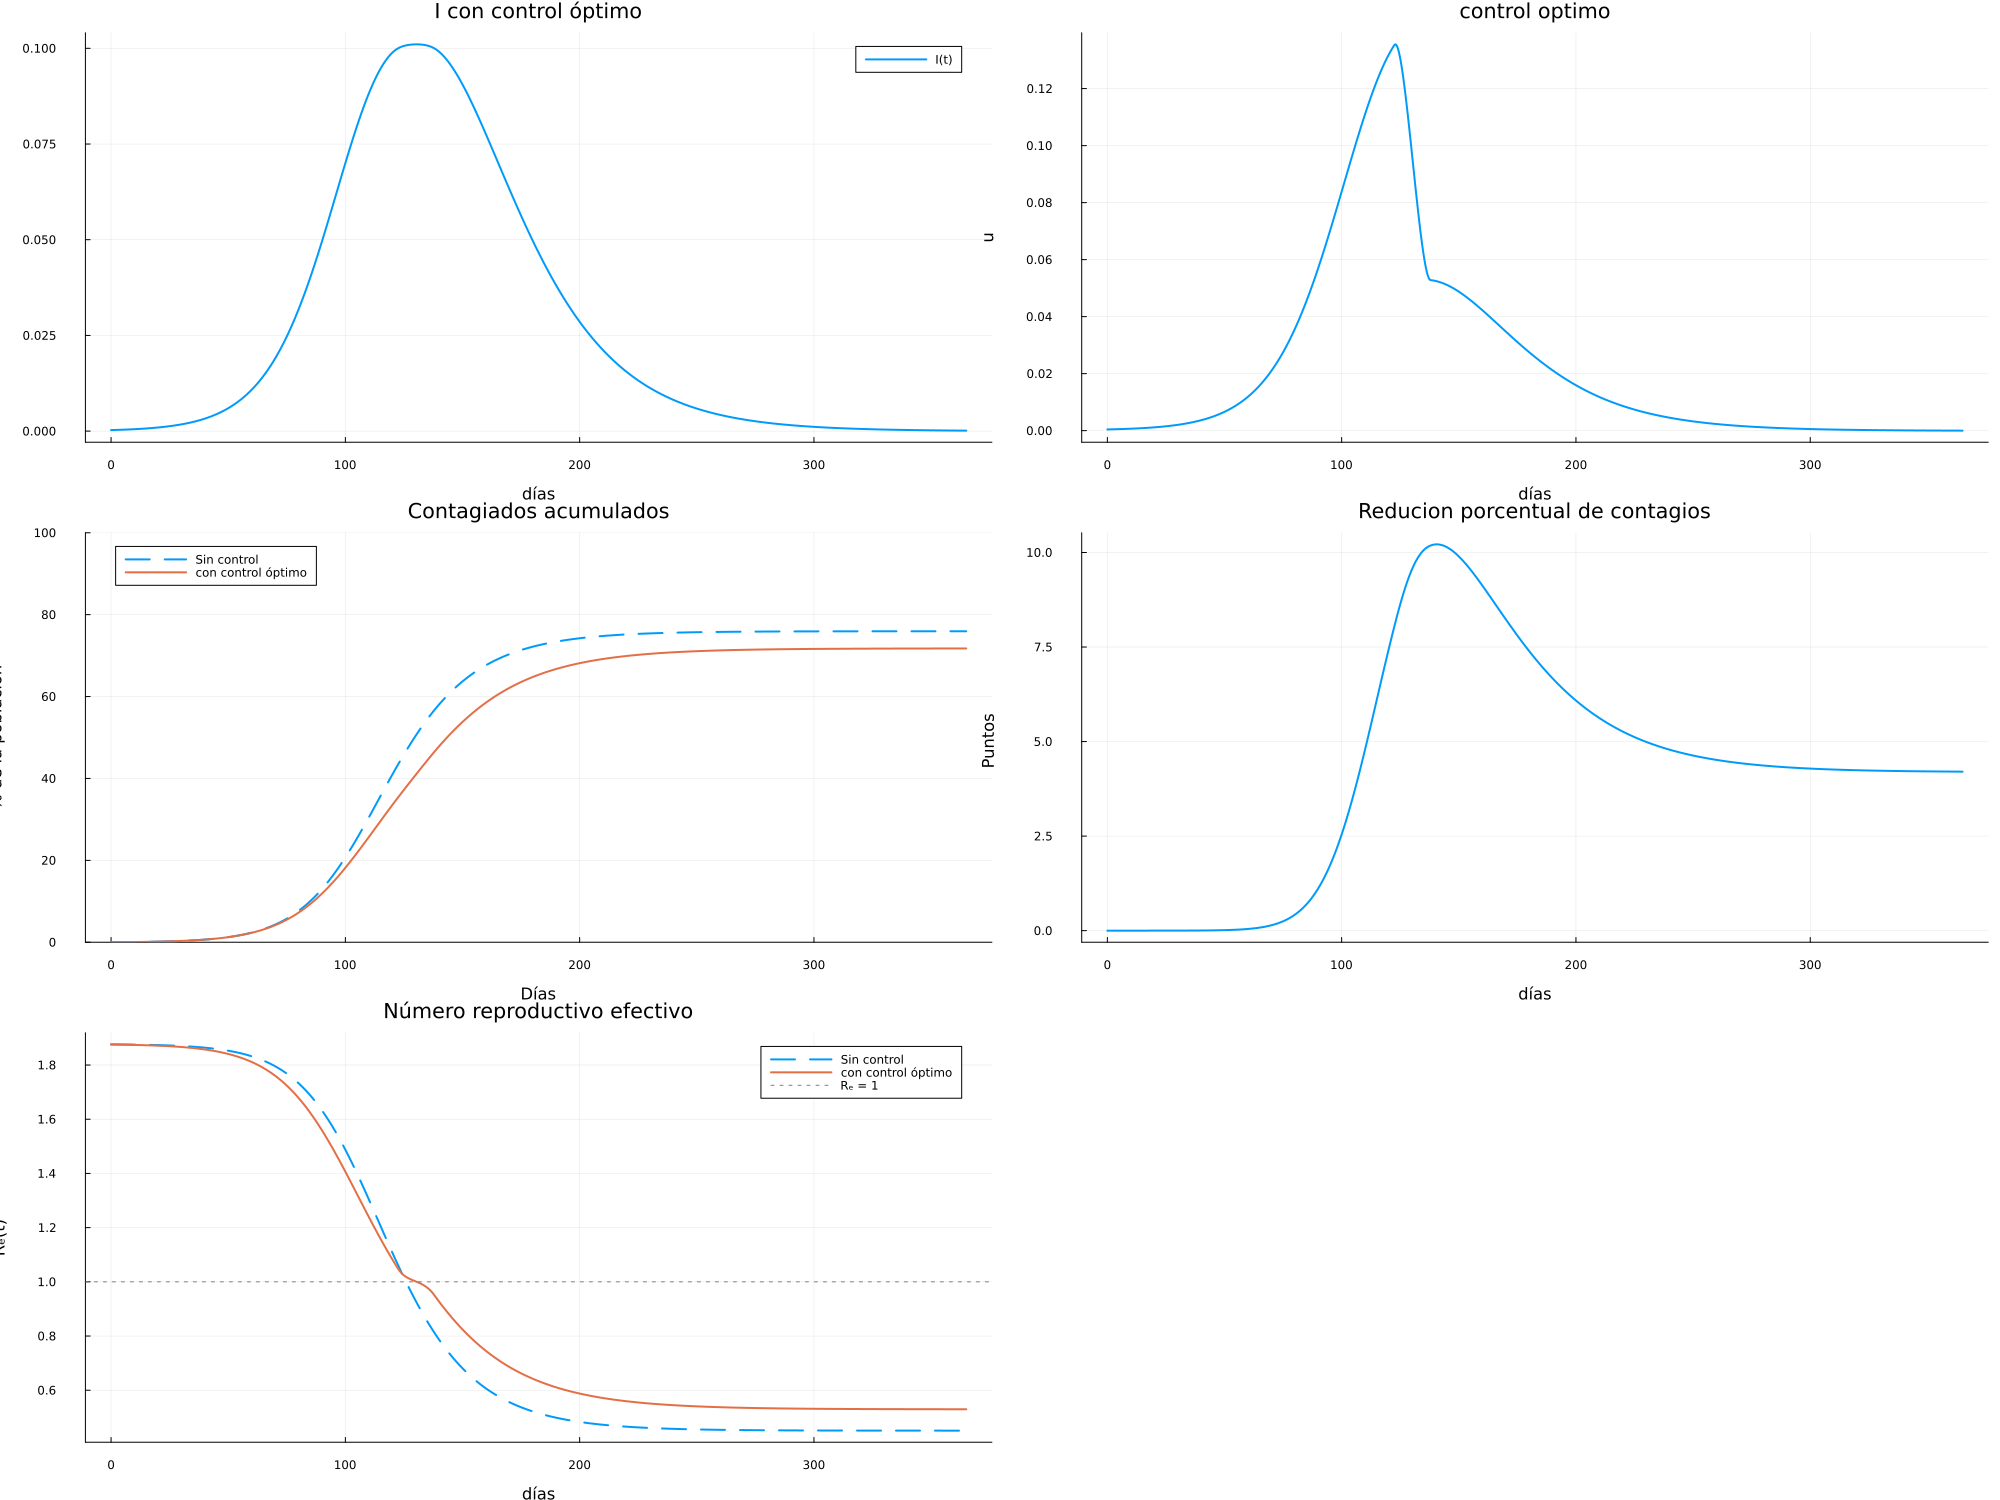

In [24]:
prob3 = ODEProblem(sistema_acoplado3!, [1 - I0, I0, p0_opt3[1], p0_opt3[2]], (0.0, T))
sol3  = solve(prob3, Tsit5(); reltol=1e-12, abstol=1e-12)
ts   = range(0, T, length=1001)
Y    = reduce(hcat, sol3.(ts))
Sv, Iv= Y[1, :], Y[2, :]
u   = control_optimo1.(Sv, Iv, Y[3, :], Y[4, :])

#grafico de infectados y el control optimal
p1 = plot(ts, Iv, lw=2, label="I(t)", xlabel="días", ylabel="Infectados",
          title="I con control óptimo")
p2 = plot(ts, u, lw=2, xlabel="días", ylabel="u", title="control optimo", legend=false)

#Porcentaje de infectados acumulados con control
C  = 100 .* ((1 - I0) .- Sv)           

# modelo sin control
sincontrol_1!(dy, y, p, t) = (dy[1] = -beta*y[1]*y[2]; dy[2] = beta*y[1]*y[2] - gamma*y[2])
Y0 = reduce(hcat, solve(ODEProblem(sincontrol_1!, [1 - I0, I0], (0.0, T)), Tsit5();
                        reltol=1e-10, abstol=1e-12).(ts))

#porcentaje de infectados acumulados sin control
C0 = 100 .* ((1 - I0) .- Y0[1, :])

#grafico de infectados acumulados
p3 = plot(ts, C0, lw=2, ls=:dash, label="Sin control", xlabel="Días",
          ylabel="% de la población", title="Contagiados acumulados", ylims=(0, 100))
plot!(p3, ts, C, lw=2, label="con control óptimo")

#diferencia porcentual de contagios
p4 = plot(ts, C0 .- C, lw=2, xlabel="días", ylabel="Puntos ",
          title="Reducion porcentual de contagios", legend=false)

#Numero reproductivo efectivo con y sin control
R0   = beta / gamma
Re   = (1 .- u) .* R0 .* Sv                  # con control óptimo (F8)
Re0  = R0 .* Y0[1, :]                        # sin control

#Grafico de numero reproductivo efectivo
p5 = plot(ts, Re0, lw=2, ls=:dash, label="Sin control",
          xlabel="días", ylabel="Rₑ(t)", title="Número reproductivo efectivo")
plot!(p5, ts, Re, lw=2, label="con control óptimo")
hline!(p5, [1.0], ls=:dot, color=:gray, label="Rₑ = 1")

k  = findfirst(<(1.0), Re)
k0 = findfirst(<(1.0), Re0)
println("Rₑ(0) = ", round(Re[1], digits=3), "   |   Rₑ(T) = ", round(Re[end], digits=3))
println("Rₑ < 1 desde t = ", isnothing(k)  ? "nunca" : round(ts[k],  digits=1), " días (con control)")
println("Rₑ < 1 desde t = ", isnothing(k0) ? "nunca" : round(ts[k0], digits=1), " días (sin control)")
println("Peak de I = ", round(maximum(Iv), digits=4), " en t = ", round(ts[argmax(Iv)], digits=1), " días")
println("u máximo  = ", round(maximum(u), digits=4),  " en t = ", round(ts[argmax(u)],  digits=1), " días")

plot(p1, p2, p3, p4,p5, layout=(3, 2), size=(2000, 1500))



### **Solución usando HJB**

Definamos las funciones $f_1(S,I,u)=-(1-u)\beta S I$ y $f_2(S,I,u)=(1-u)\beta S I - \gamma I $ notar que $f_2$ es proporcional a I y además $I_0$=0.000272  necesitamos introducir la variable $y=\ln( I) $

In [25]:
β, γ, I₀, T = 0.134, 0.0714, 0.000272, 365.0

# Malla en (S, y = ln I)
Ns, Ny = 161, 321
S_malla = collect(range(0.2, 1.0, length=Ns));                 hS = S_malla[2] - S_malla[1]
y_malla = collect(range(log(1e-6), log(0.16), length=Ny));     hy = y_malla[2] - y_malla[1]
SS = [s for s in S_malla, y in y_malla]          # matrices Ns×Ny 
II = [exp(y) for s in S_malla, y in y_malla]

# Grilla de controles 
us = collect(range(0.0, 0.2, length=41))

# Paso de tiempo por CFL
Dt0 = 0.9 / (β*0.16/hS + max(β - γ, γ)/hy)
guardar_cada = 10
Nt = guardar_cada * ceil(Int, T/(Dt0*guardar_cada))   
dt = T / Nt
Ng = Nt ÷ guardar_cada
println("Nt = $Nt,  dt = $(round(dt, digits=4))")

Nt = 2520,  dt = 0.1448


In [26]:
function diferencias_finitas(V)
    DSp = zeros(size(V)); DSp[1:end-1, :] = (V[2:end, :] - V[1:end-1, :]) / hS
    DSm = zeros(size(V)); DSm[2:end, :]   = (V[2:end, :] - V[1:end-1, :]) / hS
    Dyp = zeros(size(V)); Dyp[:, 1:end-1] = (V[:, 2:end] - V[:, 1:end-1]) / hy
    Dym = zeros(size(V)); Dym[:, 2:end]   = (V[:, 2:end] - V[:, 1:end-1]) / hy
    return DSp, DSm, Dyp, Dym
end

derivada_upwind(f, Dp, Dm) = max.(f, 0) .* Dp .+ min.(f, 0) .* Dm

# Dinámica en (S, y):  Ṡ = -(1-u)βSI ≤ 0   y   ẏ = (1-u)βS - γ  (cambia de signo)
f1(S, I, u) = -(1 - u) .* β .* S .* I
f2(S, u)    = (1 - u) .* β .* S .- γ

f2 (generic function with 1 method)

In [27]:
function resolver_hjb()
    V = zeros(Ns, Ny)                      # V(T,·) = 0
    U = zeros(Float32, Ns, Ny, Ng)         
    for n in Nt-1:-1:0
        DSp, DSm, Dyp, Dym = diferencias_finitas(V)
        H  = fill(Inf, Ns, Ny)
        ub = zeros(Ns, Ny)
        for u in us
            Hu = II .+ u^2 .+ derivada_upwind(f1(SS, II, u), DSp, DSm) .+
                              derivada_upwind(f2(SS, u),     Dyp, Dym)
            mejora = Hu .< H               
            H[mejora]  .= Hu[mejora]
            ub[mejora] .= u
        end
        V .+= dt .* H
        if n % guardar_cada == 0
            U[:, :, n ÷ guardar_cada + 1] = ub
        end
    end
    return V, U
end

@time V, U = resolver_hjb();

180.801797 seconds (8.64 M allocations: 234.341 GiB, 49.13% gc time, 1.97% compilation time)


In [28]:
function controles(t, S, I, U)
    m = clamp(round(Int, t/dt) ÷ guardar_cada + 1, 1, Ng)
    i = argmin(abs.(S_malla .- S))
    j = argmin(abs.(y_malla .- log(I)))
    return U[i, j, m]
end

function sistema!(dz, z, p, t)
    S, I, costo = z
    U = p
    u = controles(t, S, I, U)
    dz[1] = -(1 - u) * β * S * I
    dz[2] =  (1 - u) * β * S * I - γ * I
    dz[3] = I + u^2                         # costo acumulado
end

prob = ODEProblem(sistema!, [1 - I0, I0, 0.0], (0.0, T), U)
sol  = solve(prob, Tsit5(), dtmax=0.5, reltol=1e-8, abstol=1e-10)

idx_S0 = argmin(abs.(S_malla .- (1 - I0)))
idx_y0 = argmin(abs.(y_malla .- log(I0)))
println("J simulado    = ", round(sol.u[end][3], digits=4))    
println("V(0,S0,I0)    = ", round(V[idx_S0, idx_y0], digits=4)) 

J simulado    = 10.4755
V(0,S0,I0)    = 10.5681


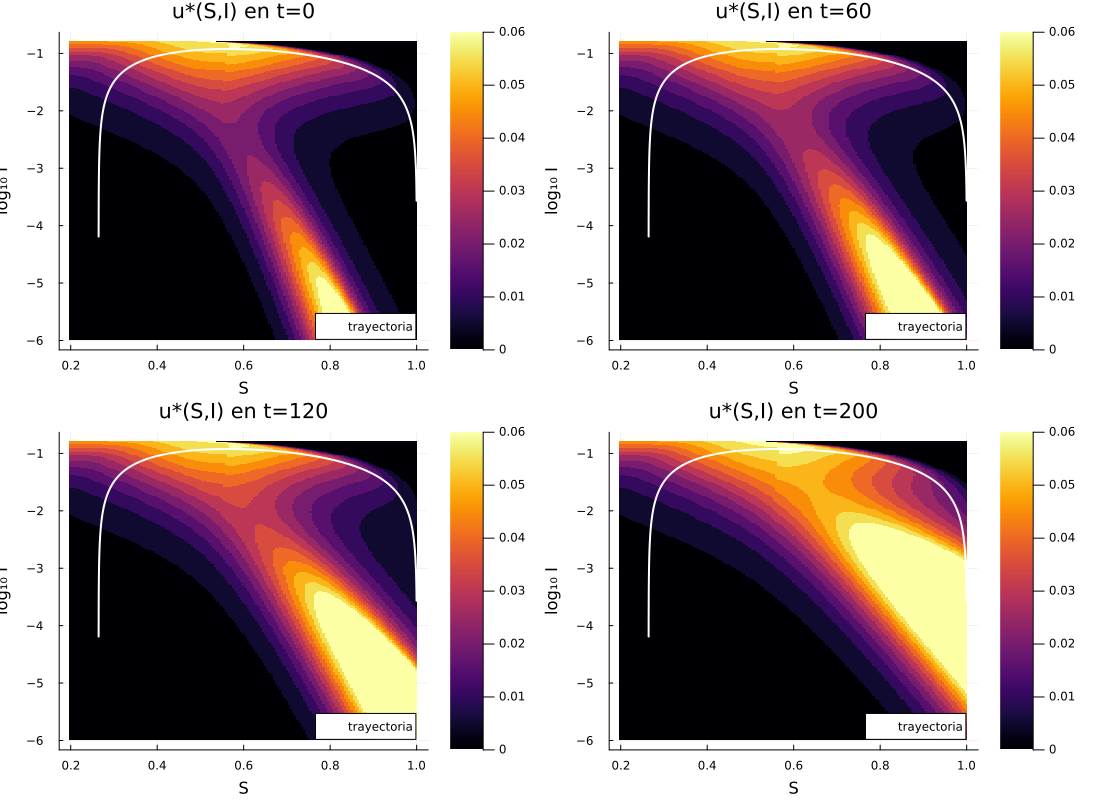

In [29]:
Ss = [s[1] for s in sol.u];  Is = [s[2] for s in sol.u]
ps = []
for t in (0.0, 60.0, 120.0, 200.0)
    m = clamp(round(Int, t/dt) ÷ guardar_cada + 1, 1, Ng)
    p = heatmap(S_malla, y_malla ./ log(10), U[:, :, m]', title="u*(S,I) en t=$(Int(t))",
                xlabel="S", ylabel="log₁₀ I", clims=(0, 0.06))
    plot!(p, Ss, log10.(Is), color=:white, lw=2, label="trayectoria")
    push!(ps, p)
end
plot(ps..., layout=(2, 2), size=(1100, 800))